<a href="https://colab.research.google.com/github/kfartem434-png/MN_Kapusta/blob/main/%D0%9B%D0%A03_%D0%9A%D0%B0%D0%BF%D1%83%D1%81%D1%82%D0%B0_3_12_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
# Ваш код:
# Імпортуйте pandas, numpy, matplotlib.pyplot, seaborn та інші потрібні бібліотеки.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import os

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame `df`.

from google.colab import files

files.upload()

df = pd.read_csv(r"/content/house_price_regression_dataset.csv")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/house_price_regression_dataset.csv'

### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [3]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.

import kagglehub

# Download latest version
path = kagglehub.dataset_download("prokshitha/home-value-insights")

df = pd.read_csv(os.path.join(path,"house_price_regression_dataset.csv"))

df.head()

100%|██████████| 26.4k/26.4k [00:00<00:00, 12.0MB/s]

Extracting files...


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [4]:
# Ваш код:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.

df.head(10)

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06
5,3944,5,3,1990,2.475930,2,8,8.797970e+05
6,3671,1,2,2012,4.911960,0,1,8.144279e+05
7,3419,1,1,1972,2.805281,1,1,7.034131e+05
8,630,3,3,1997,1.014286,1,8,1.738750e+05
9,2185,4,2,1981,3.941604,2,5,5.041765e+05


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [6]:
# Ваш код:
# Порахуйте кількість дублікатів.

df.duplicated().sum()

np.int64(0)

### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [7]:
# Ваш код:
# Виведіть кількість пропусків для кожної ознаки.

df.isna().sum(axis=0)

,0
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [8]:
# Ваш код:
# Отримайте описову статистику датасету.

df.describe()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [9]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.

frequencies_of_neigbourhood_qualities = df["Neighborhood_Quality"].value_counts().sort_index(ascending=True)
frequencies_of_neigbourhood_qualities

,count
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

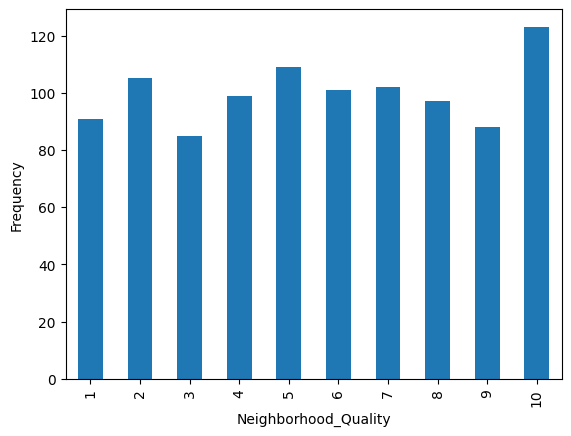

In [11]:
# Ваш код:
# Побудуйте countplot або іншу відповідну діаграму.

frequencies_of_neigbourhood_qualities.plot(kind="bar")
plt.ylabel("Frequency")
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [12]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.

frequencies_of_bathrooms = df["Num_Bathrooms"].value_counts().sort_index(ascending=True)
frequencies_of_bathrooms

,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

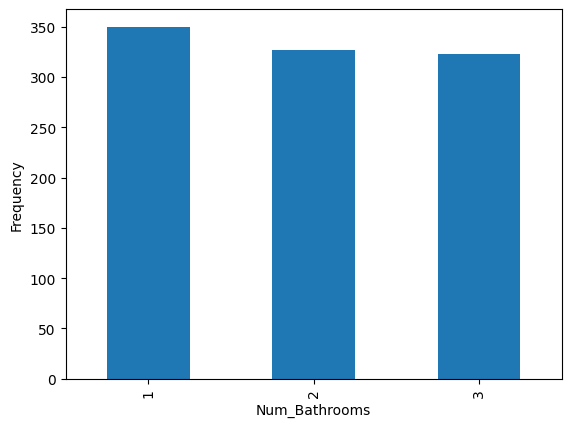

In [13]:
# Ваш код:
# Побудуйте відповідну діаграму.

frequencies_of_bathrooms.plot(kind="bar")
plt.ylabel("Frequency")
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

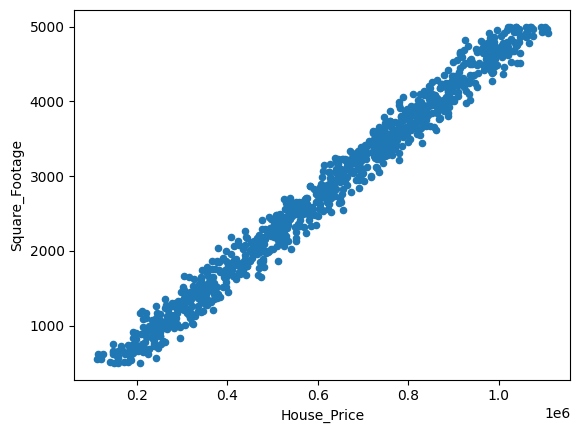

Коефіцієнт кореляції: 0.9912614505845742


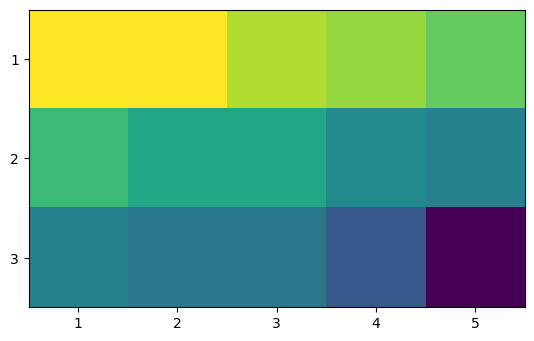

Коефіцієнт кореляції: 0.022848018876583408


In [46]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.

df[["Square_Footage","House_Price"]].plot(kind="scatter",x="House_Price",y="Square_Footage")
plt.show()
print("Коефіцієнт кореляції:",df["Square_Footage"].corr(df["House_Price"]))

fig, ax = plt.subplots()
ax.imshow(df[["Num_Bedrooms","Num_Bathrooms"]].value_counts().values.reshape([3,5]))
ax.set_xticks(np.arange(5),labels=[1,2,3,4,5])
ax.set_yticks(np.arange(3),labels=[1,2,3])
plt.show()
print("Коефіцієнт кореляції:",df["Num_Bedrooms"].corr(df["Num_Bathrooms"]))

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

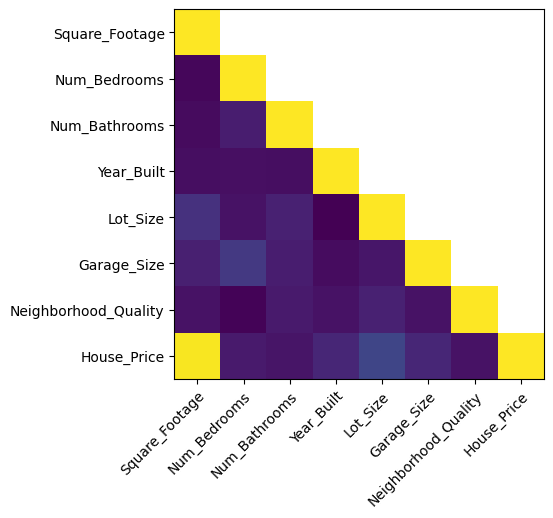

In [92]:
from numpy._core import numerictypes
from pandas.core.arrays import numeric
# Ваш код:
# Обчисліть кореляційну матрицю та побудуйте heatmap.

numeric_correlations = df.corr()

numeric_correlations_array = numeric_correlations.values

for i in range(len(numeric_correlations_array) - 1,-1,-1):
  numeric_correlations_array[i,i + 1:] = np.nan

fig, ax = plt.subplots()
ax.imshow(numeric_correlations_array)
ax.set_xticks(np.arange(len(numeric_correlations)),labels=numeric_correlations.index)
plt.setp(ax.get_xticklabels(),rotation=45,ha="right",rotation_mode="anchor")
ax.set_yticks(np.arange(len(numeric_correlations)),labels=numeric_correlations.index)
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [93]:
# Ваш код:
# Виведіть кореляції ознак із `House_Price`.

target_correlations = numeric_correlations.loc["House_Price"]

target_correlations.sort_values(ascending=False)

,House_Price
House_Price,1.000000
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [135]:
# Ваш код:
# Імпортуйте необхідні класи та функції зі scikit-learn.

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [101]:
# Ваш код:
# Створіть `X` та `y`.

X = df[df.columns.difference(["House_Price",])]
y = df["House_Price"]

display(X)
display(y)

,Garage_Size,Lot_Size,Neighborhood_Quality,Num_Bathrooms,Num_Bedrooms,Square_Footage,Year_Built
0,0,0.599637,5,1,2,1360,1981
1,1,4.753014,6,3,3,4272,2016
2,0,3.634823,9,2,1,3592,2016
3,1,2.730667,8,2,1,966,1977
4,0,4.699073,8,1,2,4926,1993
...,...,...,...,...,...,...,...
995,2,2.165110,10,1,4,3261,1978
996,1,2.977123,10,2,1,3179,1999
997,0,4.055067,2,2,4,2606,1962
998,0,1.930921,7,2,5,4723,1950


,House_Price
0,2.623829e+05
1,9.852609e+05
2,7.779774e+05
3,2.296989e+05
4,1.041741e+06
...,...
995,7.014940e+05
996,6.837232e+05
997,5.720240e+05
998,9.648653e+05


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [102]:
# Ваш код:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
  X,
  y,
  test_size=0.2,
  random_state=RANDOM_STATE
)

### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [172]:
# Ваш код:
# Створіть словник або іншу структуру з п’ятьма моделями.

models = {
  "Linear": Pipeline([
    ("scale",StandardScaler()),
    ("reg",LinearRegression())
  ]),
  "Ridge": Pipeline([
    ("scale",StandardScaler()),
    ("reg",Ridge())
  ]),
  "Lasso": Pipeline([
    ("scale",StandardScaler()),
    ("reg",Lasso())
  ]),
  "RandomForest": RandomForestRegressor(),
  "GradientBoosting": GradientBoostingRegressor()
}

models

{'Linear': Pipeline(steps=[('scale', StandardScaler()), ('reg', LinearRegression())]),
 'Ridge': Pipeline(steps=[('scale', StandardScaler()), ('reg', Ridge())]),
 'Lasso': Pipeline(steps=[('scale', StandardScaler()), ('reg', Lasso())]),
 'RandomForest': RandomForestRegressor(),
 'GradientBoosting': GradientBoostingRegressor()}

### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [173]:
# Ваш код:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.

model_predictions = dict()
model_metrics = dict()

for name, model in models.items():
  model.fit(X_train,y_train)
  prediction = model.predict(X_test)
  model_predictions[name] = prediction
  model_metrics[name] = (
    r2_score(y_test,prediction),
    mean_absolute_error(y_test,prediction),
    mean_squared_error(y_test,prediction)
  )

pd.DataFrame(model_metrics,index=["r2","MAE","MSE"])

,Linear,Ridge,Lasso,RandomForest,GradientBoosting
r2,9.984264e-01,9.984101e-01,9.984263e-01,9.939595e-01,9.965087e-01
MAE,8.174584e+03,8.241587e+03,8.174740e+03,1.597113e+04,1.230719e+04
MSE,1.014348e+08,1.024810e+08,1.014364e+08,3.893654e+08,2.250442e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

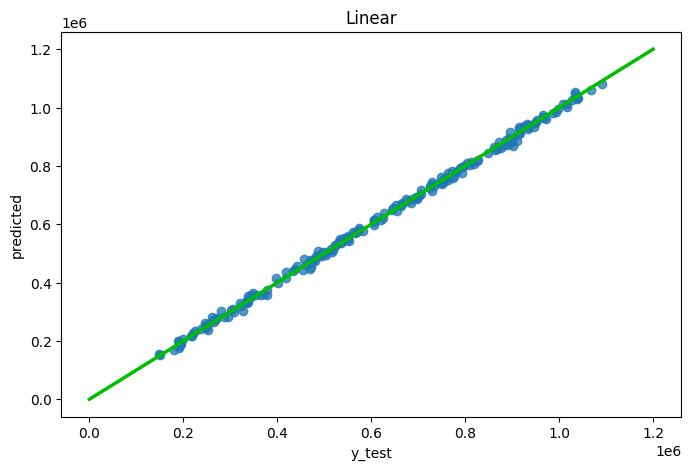

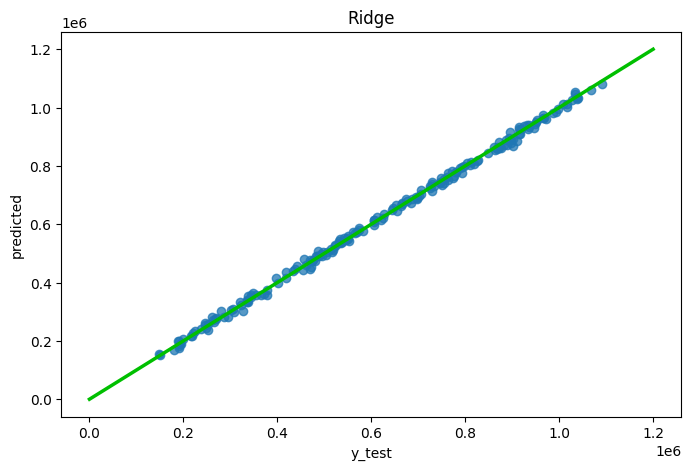

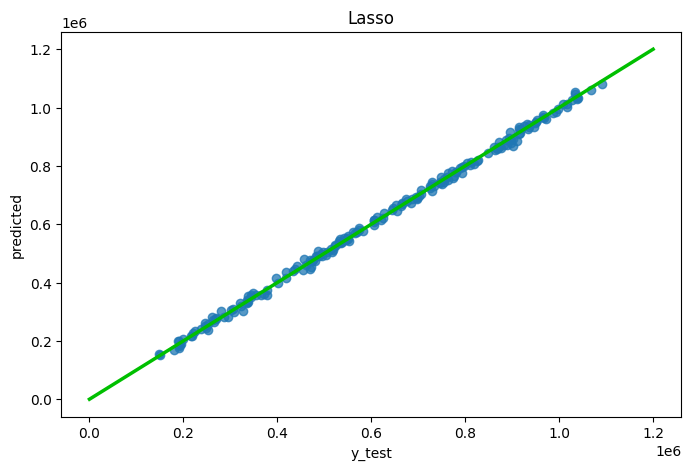

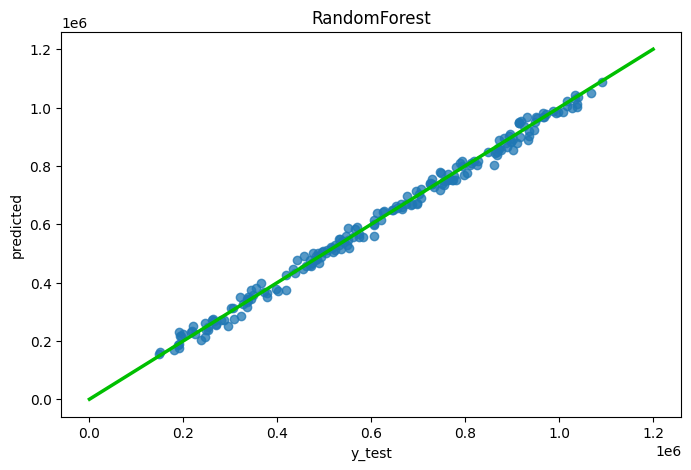

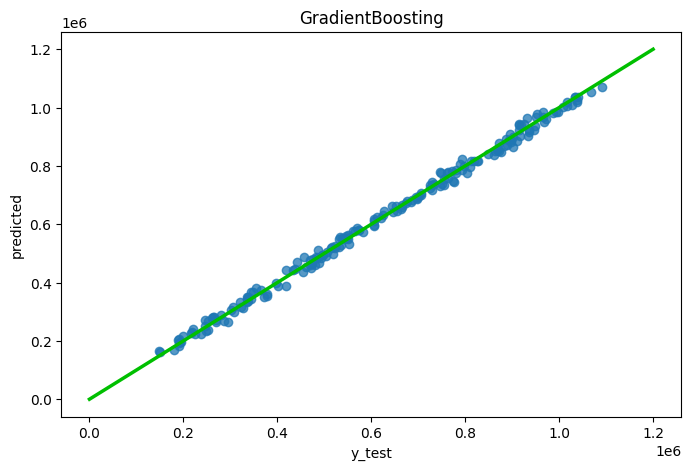

1071205.2467595644


In [133]:
# Ваш код:
# Побудуйте окремий графік для кожної моделі.

for name, prediction in model_predictions.items():
  plt.figure(figsize=(8,5))
  plt.scatter(y_test,prediction,alpha=0.75)
  plt.plot(np.linspace(0,1200000,100),np.linspace(0,1200000,100),linewidth=2.5,color=(0,0.75,0))
  plt.xlabel('y_test')
  plt.ylabel('predicted')
  plt.title(name)
  plt.show()
print(prediction.max())

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [153]:
# Ваш код:
# Створіть сітку параметрів, GridSearchCV і знайдіть найкращі параметри.

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid_random_forest = {
  "n_estimators": [10,100],
  "max_features": [10,100],
  "max_depth": [100,1000],
  "min_samples_split": [2,10]
}

random_forest_search = GridSearchCV(
  RandomForestRegressor(),
  param_grid=param_grid_random_forest,
  cv=cv,
  scoring="r2",
  n_jobs=-1
)

random_forest_search.fit(X_train,y_train)

print(random_forest_search.best_params_)

{'max_depth': 1000, 'max_features': 10, 'min_samples_split': 2, 'n_estimators': 100}


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [155]:
# Ваш код:
# Навчіть оптимізований Random Forest та обчисліть метрики.

name = "OptimisedRandomForest"
models[name] = RandomForestRegressor(
  n_estimators=100,
  max_features=10,
  max_depth=1000,
  min_samples_split=2
)

models[name].fit(X_train,y_train)

prediction = models[name].predict(X_test)
model_predictions[name] = prediction

model_metrics[name] = (
  r2_score(y_test,prediction),
  mean_absolute_error(y_test,prediction),
  mean_squared_error(y_test,prediction)
)

### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [158]:
# Ваш код:
# Виведіть результати двох моделей у зручному для порівняння вигляді.

pd.DataFrame(
  [model_metrics["RandomForest"],model_metrics["OptimisedRandomForest"]],
  index=["BasicRandomForest","OptimisedRandomForest"],
  columns=["R2","MAE","MSE"]
)

,R2,MAE,MSE
BasicRandomForest,0.994053,15901.766565,3.833455e+08
OptimisedRandomForest,0.993982,15853.111399,3.878847e+08


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Якість моделі не сильно покращилася в поріняні з базовою. Змінилися усі три використані метрики, при цьому, r2 метрика для оптимізованої моделі стала гіршою, MAE  -- зменшилася, тобто стала краще, а MSE -- збільшилася і відповідно стала гіршою. З урахуванням вищезазнчених висновків, не має доцільності використовувати оптимізовану модель.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [174]:
# Ваш код:
# Сформуйте DataFrame з фактичними та прогнозованими значеннями і розрахуйте похибку у %.

prediction_table = pd.DataFrame({"Price": y,"PredictedPrice": models["Linear"].predict(X)})
prediction_table["PercentError"] = 100*(prediction_table["PredictedPrice"] - prediction_table["Price"])/prediction_table["Price"]

rng = np.random.default_rng(seed=RANDOM_STATE)

prediction_table.iloc[rng.integers(0,len(prediction_table),10),:]

,Price,PredictedPrice,PercentError
89,2.778321e+05,2.846460e+05,2.452513
773,1.062899e+06,1.057659e+06,-0.493014
654,5.963396e+05,5.916623e+05,-0.784338
438,2.354781e+05,2.485739e+05,5.561364
433,2.144924e+05,2.236426e+05,4.265976
858,7.531862e+05,7.595705e+05,0.847648
85,1.990664e+05,1.823770e+05,-8.383815
697,6.273229e+05,6.367998e+05,1.510690
201,8.387745e+05,8.275344e+05,-1.340063
94,9.032519e+05,9.095425e+05,0.696430


In [179]:
pd.DataFrame({"Feature": df[df.columns.difference(["House_Price",])].columns,"Coeficient": models["Linear"].named_steps["reg"].coef_})

,Feature,Coeficient
0,Garage_Size,4219.449419
1,Lot_Size,19088.111033
2,Neighborhood_Quality,335.247488
3,Num_Bathrooms,6695.906775
4,Num_Bedrooms,14524.734398
5,Square_Footage,249787.914843
6,Year_Built,20662.121612


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

У даній лабораторній роботі були побудовані лінійні моделі LinearRegresion, Ridge та Lasso, а також деревопдібні регресійні моделі RandomForest та GradientBoosting. Найкращі значення метрик показала модель LinearRegresion, яка має найвищу метрику r2 та гарні показники MAE і MSE. підбір параметрів для Random Forest майже не вплинув на значення метрик, але зробив деякі з них гіршими. Точність прогнозів на тестовій вибірці не є нижчою за 93 відсотка. На ціну нерухомості сильно впливають розмір будинку, рік будівництва, кількість спалень та розмір земельної ділянки.